# 01 — Data Understanding
**Project:** AI Pipeline for Drift Prediction and Anomaly Detection in Metrological Measurement Instruments
**Standard:** ISO/IEC 17025
**Company:** L'Épi d'Or

This notebook performs a complete, automated, evidence-based understanding of the raw
metrology dataset before any cleaning or modeling decision is made. Every number in this
notebook is **computed live from the data** — nothing below is a static claim; re-running
this notebook on updated data will regenerate every table, figure and conclusion.

**Pipeline stage:** `Raw CSV → Data Validation → Data Cleaning → EDA → ...` — this notebook
covers the *Data Validation* / *Data Understanding* stage only.

**Outputs produced by this notebook:**
- `reports/data_dictionary/Data_Dictionary.xlsx`
- `reports/quality/initial_quality_report.xlsx`
- Figures in `reports/figures/01_data_understanding/`


## 1. Imports

In [1]:

import sys
import logging
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

pio.renderers.default = "notebook"
plt.rcParams["figure.facecolor"] = "white"
sns.set_style("whitegrid")

print("Imports OK —", datetime.now().isoformat(timespec="seconds"))


Imports OK — 2026-08-22T12:52:15


## 2. Configuration

Project paths and domain parameters are **never hardcoded** in this notebook: they are
read from `config/config.yaml` at the project root via `src/utils/config.py`. This makes
the notebook portable across machines (VS Code, JupyterLab, CI) as long as the project
folder structure is preserved.


In [2]:

# Make the project root importable regardless of the notebook's working directory
PROJECT_ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
project_root = None
for c in PROJECT_ROOT_CANDIDATES:
    if (c / "config" / "config.yaml").exists():
        project_root = c
        break
if project_root is None:
    raise FileNotFoundError(
        "Could not find config/config.yaml from the current working directory. "
        "Run this notebook from the project root or from notebooks/."
    )
sys.path.insert(0, str(project_root))

from src.utils.config import load_config  # noqa: E402

cfg = load_config()

DATA_RAW = project_root / cfg["paths"]["data_raw"]
DATA_INTERIM = project_root / cfg["paths"]["data_interim"]
DATA_PROCESSED = project_root / cfg["paths"]["data_processed"]
REPORTS_FIGURES = project_root / cfg["paths"]["reports_figures"] / "01_data_understanding"
REPORTS_DICT = project_root / cfg["paths"]["reports_data_dictionary"]
REPORTS_QUALITY = project_root / cfg["paths"]["reports_quality"]
LOGS_DIR = project_root / cfg["paths"]["logs"]

for d in [REPORTS_FIGURES, REPORTS_DICT, REPORTS_QUALITY, LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = cfg["expected_columns"]
EXCLUDE_KEYWORDS = cfg["dataset_discovery"]["exclude_keywords"]
SPLIT_KEYWORDS = cfg["dataset_discovery"]["split_keywords"]
MIN_YEAR = cfg["plausibility"]["min_year"]
MAX_YEAR = cfg["plausibility"]["max_year"]

# Logging: every automated decision this notebook makes (which file was
# selected, which rows were flagged) is logged, not just printed, for audit.
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[
        logging.FileHandler(LOGS_DIR / "01_data_understanding.log", mode="w"),
        logging.StreamHandler(sys.stdout),
    ],
)
logger = logging.getLogger("01_data_understanding")

logger.info("Project root: %s", project_root)
logger.info("Expected columns: %s", EXPECTED_COLUMNS)


2026-08-22 12:52:16,060 | INFO | Project root: /home/claude/project2/metrology-ai-pipeline


2026-08-22 12:52:16,062 | INFO | Expected columns: ['id_instrument', 'lab', 'annee', 'point', 'consigne', 'valeur_reference', 'incertitude', 'EMT_basse', 'EMT_haute', 'min', 'max', 'conforme']


## 3. Load Dataset

### 3.1 Automatic dataset discovery

This notebook does **not** hardcode a filename. It scans `data/interim/` and
`data/processed/` for candidate CSV files, reads only their header row, and scores each
candidate against the expected metrology schema declared in `config.yaml`. Log,
traceability and audit files (produced by the extraction pipeline) are automatically
excluded, and — when several valid datasets exist (e.g. a full organized dataset vs. its
train/test splits) — the notebook prefers the complete, non-split dataset for a full
Data Understanding pass, and logs exactly why.


In [3]:

def score_candidate(csv_path: Path, expected_columns: list[str]) -> dict:
    '''Read only the header of a CSV and score it against the expected schema.'''
    try:
        header_df = pd.read_csv(csv_path, nrows=0)
    except Exception as e:
        return {"path": csv_path, "readable": False, "error": str(e), "score": -1}

    columns = list(header_df.columns)
    overlap = set(c.strip() for c in columns) & set(expected_columns)
    name_lower = csv_path.stem.lower()

    is_excluded = any(kw in name_lower for kw in EXCLUDE_KEYWORDS)
    is_split = any(kw in name_lower for kw in SPLIT_KEYWORDS)

    try:
        n_rows = sum(1 for _ in open(csv_path, encoding="utf-8-sig")) - 1
    except Exception:
        n_rows = -1

    return {
        "path": csv_path,
        "readable": True,
        "n_columns_found": len(columns),
        "n_expected_columns_matched": len(overlap),
        "matched_columns": sorted(overlap),
        "is_excluded_by_keyword": is_excluded,
        "is_split_or_augmented": is_split,
        "n_rows": n_rows,
    }


search_dirs = [DATA_INTERIM, DATA_PROCESSED]
candidate_files = []
for d in search_dirs:
    candidate_files.extend(sorted(d.glob("*.csv")))

logger.info("Found %d candidate CSV file(s) in %s", len(candidate_files), search_dirs)

candidates = [score_candidate(p, EXPECTED_COLUMNS) for p in candidate_files]
candidates_df = pd.DataFrame(candidates)
display(candidates_df[["path", "readable", "n_columns_found", "n_expected_columns_matched",
                        "is_excluded_by_keyword", "is_split_or_augmented", "n_rows"]])


2026-08-22 12:52:16,073 | INFO | Found 10 candidate CSV file(s) in [PosixPath('/home/claude/project2/metrology-ai-pipeline/data/interim'), PosixPath('/home/claude/project2/metrology-ai-pipeline/data/processed')]


,path,readable,n_columns_found,n_expected_columns_matched,is_excluded_by_keyword,is_split_or_augmented,n_rows
0,/home/claude/project2/metrology-ai-pipeline/da...,True,7,1,True,False,49
1,/home/claude/project2/metrology-ai-pipeline/da...,True,12,12,False,False,767
2,/home/claude/project2/metrology-ai-pipeline/da...,True,6,4,True,False,6
3,/home/claude/project2/metrology-ai-pipeline/da...,True,15,4,True,False,767
4,/home/claude/project2/metrology-ai-pipeline/da...,True,23,12,False,False,763
5,/home/claude/project2/metrology-ai-pipeline/da...,True,44,11,False,False,763
6,/home/claude/project2/metrology-ai-pipeline/da...,True,17,8,False,False,763
7,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,133
8,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,2109
9,/home/claude/project2/metrology-ai-pipeline/da...,True,13,12,False,True,528


In [4]:

# Selection rule (fully automatic, no filename hardcoded):
#  1. Keep only readable candidates.
#  2. Drop candidates excluded by keyword (log / tracabilite / audit / exclu files).
#  3. Among the remainder, prefer full (non split/augmented) datasets that match
#     the complete expected schema — this is the right dataset for a full,
#     unbiased Data Understanding pass.
#  4. If no full dataset is found, fall back to the split dataset with the
#     highest schema match and highest row count.
valid = [c for c in candidates if c.get("readable") and not c.get("is_excluded_by_keyword")]
if not valid:
    raise RuntimeError("No valid metrology dataset candidate found in data/interim or data/processed.")

full_matches = [c for c in valid
                if c["n_expected_columns_matched"] == len(EXPECTED_COLUMNS)
                and not c["is_split_or_augmented"]]

if full_matches:
    chosen = max(full_matches, key=lambda c: c["n_rows"])
    logger.info("Selected FULL organized dataset (non-split): %s", chosen["path"].name)
else:
    chosen = max(valid, key=lambda c: (c["n_expected_columns_matched"], c["n_rows"]))
    logger.warning("No full non-split dataset found — falling back to: %s", chosen["path"].name)

DATASET_PATH = chosen["path"]
logger.info("DATASET SELECTED: %s (%d rows, %d/%d expected columns matched)",
            DATASET_PATH, chosen["n_rows"], chosen["n_expected_columns_matched"], len(EXPECTED_COLUMNS))

print(f"\n>>> Dataset automatically selected: {DATASET_PATH.relative_to(project_root)}\n")


2026-08-22 12:52:16,127 | INFO | Selected FULL organized dataset (non-split): ILA_donnees_organisees.csv


2026-08-22 12:52:16,129 | INFO | DATASET SELECTED: /home/claude/project2/metrology-ai-pipeline/data/interim/ILA_donnees_organisees.csv (767 rows, 12/12 expected columns matched)



>>> Dataset automatically selected: data/interim/ILA_donnees_organisees.csv



In [5]:

df = pd.read_csv(DATASET_PATH)
logger.info("Loaded dataset with shape %s", df.shape)
print(f"Loaded shape: {df.shape}")


2026-08-22 12:52:16,139 | INFO | Loaded dataset with shape (767, 12)


Loaded shape: (767, 12)


### 3.2 First rows, random sample, and last rows

In [6]:

print("First 5 rows:")
display(df.head(5))


First 5 rows:


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
0,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,1,NaN,24.10,0.07,24.0,26.0,24.03,24.17,conforme
1,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2020,2,NaN,24.00,0.07,24.0,26.0,23.93,24.07,non conforme
2,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme
3,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2021,2,NaN,23.81,0.20,24.0,26.0,23.61,24.01,non conforme
4,INST-03B-CHAMBREDEFERMENTATION,lab 03B,2022,1,NaN,24.08,0.20,24.0,26.0,23.88,24.28,non conforme


In [7]:

print("Random 5 rows (seeded for reproducibility):")
display(df.sample(n=min(5, len(df)), random_state=42))


Random 5 rows (seeded for reproducibility):


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
667,INST-83ACONG,lab 83A cong,2020,9.0,-20.0,-22.0,1.10,2.0,8.0,-23.10,-20.90,non conforme
324,INST-19D,lab19D,2024,5,36.5,36.9,0.38,36.0,38.0,36.52,37.28,conforme
623,INST-83,lab 83,2022,1,NaN,3.8,1.67,2.0,8.0,2.13,5.47,conforme
689,INST-83ACONG,lab 83Acong,2023,4,-20.0,-21.5,2.69,-26.0,-14.0,-24.19,-18.81,conforme
521,INST-62,lab 62,2022,7,25.0,24.6,0.38,24.0,26.0,24.22,24.98,conforme


In [8]:

print("Last 5 rows:")
display(df.tail(5))


Last 5 rows:


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
762,INST-84,lab 84-2025,2025,5,170.0,169.4,0.70,160.0,180.0,168.70,170.10,conforme
763,INST-84,lab 84-2025,2025,6,170.0,169.7,0.68,160.0,180.0,169.02,170.38,conforme
764,INST-84,lab 84-2025,2025,7,170.0,170.4,0.69,160.0,180.0,169.71,171.09,conforme
765,INST-84,lab 84-2025,2025,8,170.0,172.4,0.69,160.0,180.0,171.71,173.09,conforme
766,INST-84,lab 84-2025,2025,9,170.0,173.4,0.71,160.0,180.0,172.69,174.11,conforme


## 4. Dataset Overview

### 4.1 Shape and memory usage

In [9]:

n_rows, n_cols = df.shape
memory_bytes = df.memory_usage(deep=True).sum()
memory_kb = memory_bytes / 1024

overview = pd.DataFrame({
    "metric": ["n_rows", "n_columns", "memory_usage_KB"],
    "value": [n_rows, n_cols, round(memory_kb, 2)],
})
display(overview)
logger.info("Shape: %d rows x %d columns | Memory: %.2f KB", n_rows, n_cols, memory_kb)


,metric,value
0,n_rows,767.00
1,n_columns,12.00
2,memory_usage_KB,212.08


2026-08-22 12:52:16,191 | INFO | Shape: 767 rows x 12 columns | Memory: 212.08 KB


### 4.2 Columns and data types

In [10]:

dtypes_df = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(t) for t in df.dtypes],
})
display(dtypes_df)


,column,dtype
0,id_instrument,object
1,lab,object
2,annee,int64
3,point,object
4,consigne,float64
5,valeur_reference,float64
6,incertitude,float64
7,EMT_basse,float64
8,EMT_haute,float64
9,min,float64


### 4.3 Missing values

In [11]:

missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    "column": df.columns,
    "missing_count": missing_count.values,
    "missing_pct": missing_pct.values,
}).sort_values("missing_pct", ascending=False).reset_index(drop=True)
display(missing_df)


,column,missing_count,missing_pct
0,consigne,263,34.29
1,conforme,106,13.82
2,EMT_basse,32,4.17
3,EMT_haute,32,4.17
4,valeur_reference,1,0.13
5,annee,0,0.00
6,lab,0,0.00
7,id_instrument,0,0.00
8,point,0,0.00
9,incertitude,0,0.00


### 4.4 Duplicates

In [12]:

n_full_duplicates = int(df.duplicated(keep=False).sum())
print(f"Fully duplicated rows (all columns identical): {n_full_duplicates}")

key_cols = [c for c in ["id_instrument", "annee", "point"] if c in df.columns]
if key_cols:
    n_key_duplicates = int(df.duplicated(subset=key_cols, keep=False).sum())
    print(f"Duplicated on business key {key_cols}: {n_key_duplicates}")
    if n_key_duplicates > 0:
        display(df[df.duplicated(subset=key_cols, keep=False)].sort_values(key_cols).head(20))


Fully duplicated rows (all columns identical): 0
Duplicated on business key ['id_instrument', 'annee', 'point']: 6


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
96,INST-11B,LAB 11B,2022,1,100.0,100.9,0.42,NaN,NaN,100.48,101.32,NaN
97,INST-11B,LAB 11B,2022,1,99.5,100.4,0.42,NaN,NaN,99.98,100.82,NaN
98,INST-11B,LAB 11B,2022,2,100.0,100.9,0.38,NaN,NaN,100.52,101.28,NaN
99,INST-11B,LAB 11B,2022,2,99.5,100.4,0.38,NaN,NaN,100.02,100.78,NaN
100,INST-11B,LAB 11B,2022,3,100.0,100.9,0.39,NaN,NaN,100.51,101.29,NaN
101,INST-11B,LAB 11B,2022,3,99.5,100.4,0.39,NaN,NaN,100.01,100.79,NaN


### 4.5 Unique values and cardinality

In [13]:

cardinality_df = pd.DataFrame({
    "column": df.columns,
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    "n_total": len(df),
})
cardinality_df["unique_pct"] = (cardinality_df["n_unique"] / cardinality_df["n_total"] * 100).round(2)
cardinality_df["is_constant"] = cardinality_df["n_unique"] <= 1
cardinality_df["is_quasi_constant"] = cardinality_df["unique_pct"] < 1.0
cardinality_df = cardinality_df.sort_values("n_unique", ascending=False).reset_index(drop=True)
display(cardinality_df)


,column,n_unique,n_total,unique_pct,is_constant,is_quasi_constant
0,max,547,767,71.32,False,False
1,min,541,767,70.53,False,False
2,valeur_reference,319,767,41.59,False,False
3,incertitude,159,767,20.73,False,False
4,lab,37,767,4.82,False,False
5,consigne,31,767,4.04,False,False
6,point,23,767,3.00,False,False
7,id_instrument,22,767,2.87,False,False
8,EMT_basse,15,767,1.96,False,False
9,EMT_haute,14,767,1.83,False,False


### 4.6 `df.info()`

In [14]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_instrument     767 non-null    object 
 1   lab               767 non-null    object 
 2   annee             767 non-null    int64  
 3   point             767 non-null    object 
 4   consigne          504 non-null    float64
 5   valeur_reference  766 non-null    float64
 6   incertitude       767 non-null    float64
 7   EMT_basse         735 non-null    float64
 8   EMT_haute         735 non-null    float64
 9   min               767 non-null    float64
 10  max               767 non-null    float64
 11  conforme          661 non-null    object 
dtypes: float64(7), int64(1), object(4)
memory usage: 72.0+ KB


### 4.7 `df.describe()` — numeric and categorical

In [15]:

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols]

print("Numeric columns:", numeric_cols)
print("Categorical / text columns:", categorical_cols)

print("\nNumeric summary:")
display(df[numeric_cols].describe().T)

print("\nCategorical summary:")
display(df[categorical_cols].describe().T)


Numeric columns: ['annee', 'consigne', 'valeur_reference', 'incertitude', 'EMT_basse', 'EMT_haute', 'min', 'max']
Categorical / text columns: ['id_instrument', 'lab', 'point', 'conforme']

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
annee,767.0,2022.614081,1.678371,2020.00,2021.00,2023.000,2024.00,2025.00
consigne,504.0,98.549405,146.611786,-20.00,25.00,41.500,132.80,560.00
valeur_reference,766.0,82.252742,128.722950,-24.00,6.20,37.385,130.50,1003.00
incertitude,767.0,0.897562,0.861383,0.07,0.38,0.510,1.06,5.85
EMT_basse,735.0,79.148980,124.568787,-26.00,2.00,36.000,130.00,540.00
EMT_haute,735.0,84.389796,128.155153,-14.00,8.00,38.000,133.00,560.00
min,767.0,81.252203,128.324132,-25.48,5.00,36.870,130.11,1002.48
max,767.0,83.039309,129.027263,-22.70,7.68,38.060,130.86,1003.52



Categorical summary:


,count,unique,top,freq
id_instrument,767,22,INST-47A,60
lab,767,37,lab 47b,50
point,767,23,1,90
conforme,661,2,conforme,534


## 5. Automatic Data Dictionary

The domain (business / metrology) meaning of each **known** ISO/IEC 17025 metrology
column is documented below as reference metadata (this is domain documentation, not a
computed statistic). Every quantitative field of the dictionary — detected type, missing
%, unique %, expected range, potential ML usage/preprocessing — is computed live from
`df`. Any column not in the known metrology schema still gets a full row, generated
generically, so the dictionary never silently drops a column.


In [16]:

# Domain metadata for the known ISO/IEC 17025 metrology schema.
# This dict documents business/metrology MEANING (fixed domain knowledge);
# every other field of the dictionary below is computed from the data.
DOMAIN_METADATA = {
    "id_instrument": dict(
        description="Unique identifier of the measuring instrument.",
        business_meaning="Primary key used to group all historical measurements of one physical instrument.",
        metrology_meaning="Instrument identity — the entity whose drift/anomaly is being tracked over time.",
        expected_range="Non-null string, unique per physical instrument.",
        potential_ml_usage="Grouping key for per-instrument feature engineering (trend, rolling stats); NOT a model feature itself (high cardinality identifier).",
        potential_preprocessing="Normalize formatting (case, whitespace); verify 1:1 mapping with 'lab'.",
    ),
    "lab": dict(
        description="Laboratory / instrument location label as recorded in the source Excel file.",
        business_meaning="Identifies which laboratory or production line the instrument belongs to.",
        metrology_meaning="Contextual grouping for control-chart analysis; not itself a metrology quantity.",
        expected_range="Non-null string.",
        potential_ml_usage="Categorical feature (encoded) if lab-specific effects are suspected.",
        potential_preprocessing="Normalize text (accents, case, trailing year suffixes like '-2025') before using as a categorical feature.",
    ),
    "annee": dict(
        description="Calibration/verification campaign year.",
        business_meaning="Identifies which yearly campaign a measurement belongs to.",
        metrology_meaning="Time axis for drift analysis across calibration cycles.",
        expected_range=f"Integer, plausibly between {MIN_YEAR} and {MAX_YEAR}.",
        potential_ml_usage="Base for time-since / campaign-count features; not used directly as a raw feature.",
        potential_preprocessing="Validate range; combine with 'point' to build a proper chronological order.",
    ),
    "point": dict(
        description="Measurement point identifier within a campaign (e.g. a calibration point number or a named position).",
        business_meaning="Distinguishes multiple measurement points taken during the same calibration/verification.",
        metrology_meaning="A single point on the instrument's calibration curve, or a named test position.",
        expected_range="Expected numeric point index, but may contain text labels (observed in source data).",
        potential_ml_usage="Ordering key within a campaign; needs type harmonization before any numeric use.",
        potential_preprocessing="Harmonize mixed numeric/text values ('1' vs '1.0' vs 'au fond') into a single consistent representation.",
    ),
    "consigne": dict(
        description="Nominal/setpoint value the instrument is expected to indicate.",
        business_meaning="The target value used to assess how far the instrument's indication is from what it should read.",
        metrology_meaning="Nominal indication value, compared against the calibration reference.",
        expected_range="Numeric, same physical unit and order of magnitude as 'valeur_reference'.",
        potential_ml_usage="Feature for computing indication error (consigne vs valeur_reference).",
        potential_preprocessing="Impute or flag missing values (frequently absent when the reference itself was used directly as the nominal value).",
    ),
    "valeur_reference": dict(
        description="Reference (traceable, etalon) value recorded during calibration/verification.",
        business_meaning="The 'ground truth' value the instrument is compared against.",
        metrology_meaning="Traceable reference value used to compute the instrument's error and conformity.",
        expected_range="Numeric, instrument-category dependent.",
        potential_ml_usage="Core input for drift/error computation; central regression target driver.",
        potential_preprocessing="Outlier screening per instrument category; must never be imputed silently (a fabricated reference value would invalidate conformity).",
    ),
    "incertitude": dict(
        description="Measurement uncertainty associated with the reference value.",
        business_meaning="Quantifies the confidence interval around the recorded reference value.",
        metrology_meaning="Combined measurement uncertainty (ISO/IEC 17025), used to compute min/max bounds and to weight augmentation noise.",
        expected_range="Strictly positive numeric value.",
        potential_ml_usage="Feature 'uncertainty_ratio' (uncertainty / EMT width); used as noise scale in scientifically-grounded data augmentation.",
        potential_preprocessing="Flag zero/negative/missing values as physically impossible.",
    ),
    "EMT_basse": dict(
        description="Lower bound of the Maximum Permissible Error (EMT) tolerance interval.",
        business_meaning="Regulatory/specification lower conformity limit for this instrument category.",
        metrology_meaning="Lower EMT bound; instrument is non-conformant if min falls below this value.",
        expected_range="Numeric; must be strictly lower than EMT_haute.",
        potential_ml_usage="Reference for 'distance_to_EMT' feature and for the deterministic rule engine (chapter 4 of the specification).",
        potential_preprocessing="Flag rows where EMT_basse >= EMT_haute as impossible.",
    ),
    "EMT_haute": dict(
        description="Upper bound of the Maximum Permissible Error (EMT) tolerance interval.",
        business_meaning="Regulatory/specification upper conformity limit for this instrument category.",
        metrology_meaning="Upper EMT bound; instrument is non-conformant if max exceeds this value.",
        expected_range="Numeric; must be strictly higher than EMT_basse.",
        potential_ml_usage="Reference for 'distance_to_EMT' feature and rule engine.",
        potential_preprocessing="Flag rows where EMT_haute <= EMT_basse as impossible.",
    ),
    "min": dict(
        description="Minimum bound of the measurement (typically valeur_reference − incertitude).",
        business_meaning="Lower edge of the plausible measurement interval used for the conformity decision.",
        metrology_meaning="Lower measurement bound compared against EMT_basse for conformity.",
        expected_range="Numeric; must be lower than or equal to 'max'.",
        potential_ml_usage="Direct input to the conformity rule; candidate regression feature.",
        potential_preprocessing="Flag rows where min > max as impossible / corrupted source data.",
    ),
    "max": dict(
        description="Maximum bound of the measurement (typically valeur_reference + incertitude).",
        business_meaning="Upper edge of the plausible measurement interval used for the conformity decision.",
        metrology_meaning="Upper measurement bound compared against EMT_haute for conformity.",
        expected_range="Numeric; must be greater than or equal to 'min'.",
        potential_ml_usage="Direct input to the conformity rule; candidate regression feature.",
        potential_preprocessing="Flag rows where max < min as impossible / corrupted source data.",
    ),
    "conforme": dict(
        description="Conformity verdict for this measurement (conforme / non conforme).",
        business_meaning="The quality decision actually recorded for this measurement point.",
        metrology_meaning="Ground truth conformity label, derivable from min/max vs EMT and usable to cross-validate the rule engine.",
        expected_range="Categorical: {'conforme', 'non conforme'} (missing values observed in source data).",
        potential_ml_usage="Candidate label to validate the deterministic rule engine and as an auxiliary classification target.",
        potential_preprocessing="Normalize casing/spelling; investigate missing values (may indicate an unrecorded verdict, not a true unknown).",
    ),
}

GENERIC_METADATA = dict(
    description="Column not part of the documented ISO/IEC 17025 metrology schema.",
    business_meaning="To be reviewed with the metrology team.",
    metrology_meaning="To be reviewed with the metrology team.",
    expected_range="Unknown — derived automatically from observed data below.",
    potential_ml_usage="To be assessed once its business meaning is clarified.",
    potential_preprocessing="To be assessed once its business meaning is clarified.",
)
print(f"Domain metadata documented for {len(DOMAIN_METADATA)} known columns.")


Domain metadata documented for 12 known columns.


In [17]:

def detect_semantic_type(series: pd.Series) -> str:
    '''Best-effort semantic type detection, purely from observed data.'''
    non_null = series.dropna()
    if non_null.empty:
        return "empty"
    if pd.api.types.is_numeric_dtype(series):
        return "numeric"
    # Try numeric coercion on text columns (catches mixed-type columns like 'point')
    coerced = pd.to_numeric(non_null, errors="coerce")
    frac_numeric = coerced.notna().mean()
    if frac_numeric > 0.9:
        return "numeric-like text (mostly convertible)"
    if frac_numeric > 0.3:
        return "mixed numeric/text"
    if non_null.nunique() <= 20:
        return "categorical"
    return "free text"


def suggest_preprocessing(col: str, series: pd.Series, semantic_type: str, missing_pct: float) -> str:
    suggestions = []
    if missing_pct > 0:
        suggestions.append(f"handle {missing_pct:.1f}% missing values (imputation or explicit flag, never silent fill for measurement fields)")
    if semantic_type == "mixed numeric/text":
        suggestions.append("harmonize mixed numeric/text representations into one consistent type")
    if semantic_type == "numeric-like text (mostly convertible)":
        suggestions.append("coerce to numeric with pd.to_numeric(errors='coerce') and audit non-convertible rows")
    if semantic_type == "categorical":
        suggestions.append("normalize text (case/accents/whitespace) before encoding")
    return "; ".join(suggestions) if suggestions else "none identified from automated checks"


rows = []
for col in df.columns:
    series = df[col]
    meta = DOMAIN_METADATA.get(col, GENERIC_METADATA)
    semantic_type = detect_semantic_type(series)
    missing_pct = float((series.isna().mean() * 100).round(2))
    unique_pct = round(series.nunique(dropna=True) / len(series) * 100, 2)

    rows.append({
        "name": col,
        "detected_dtype": str(series.dtype),
        "detected_semantic_type": semantic_type,
        "description": meta["description"],
        "business_meaning": meta["business_meaning"],
        "metrology_meaning": meta["metrology_meaning"],
        "expected_range": meta["expected_range"],
        "missing_pct": missing_pct,
        "unique_pct": unique_pct,
        "potential_ml_usage": meta["potential_ml_usage"],
        "potential_preprocessing": meta["potential_preprocessing"] if col in DOMAIN_METADATA
                                    else suggest_preprocessing(col, series, semantic_type, missing_pct),
    })

data_dictionary = pd.DataFrame(rows)
display(data_dictionary)


,name,detected_dtype,detected_semantic_type,description,business_meaning,metrology_meaning,expected_range,missing_pct,unique_pct,potential_ml_usage,potential_preprocessing
0,id_instrument,object,free text,Unique identifier of the measuring instrument.,Primary key used to group all historical measu...,Instrument identity — the entity whose drift/a...,"Non-null string, unique per physical instrument.",0.00,2.87,Grouping key for per-instrument feature engine...,"Normalize formatting (case, whitespace); verif..."
1,lab,object,free text,Laboratory / instrument location label as reco...,Identifies which laboratory or production line...,Contextual grouping for control-chart analysis...,Non-null string.,0.00,4.82,Categorical feature (encoded) if lab-specific ...,"Normalize text (accents, case, trailing year s..."
2,annee,int64,numeric,Calibration/verification campaign year.,Identifies which yearly campaign a measurement...,Time axis for drift analysis across calibratio...,"Integer, plausibly between 2000 and 2035.",0.00,0.78,Base for time-since / campaign-count features;...,Validate range; combine with 'point' to build ...
3,point,object,numeric-like text (mostly convertible),Measurement point identifier within a campaign...,Distinguishes multiple measurement points take...,A single point on the instrument's calibration...,"Expected numeric point index, but may contain ...",0.00,3.00,Ordering key within a campaign; needs type har...,Harmonize mixed numeric/text values ('1' vs '1...
4,consigne,float64,numeric,Nominal/setpoint value the instrument is expec...,The target value used to assess how far the in...,"Nominal indication value, compared against the...","Numeric, same physical unit and order of magni...",34.29,4.04,Feature for computing indication error (consig...,Impute or flag missing values (frequently abse...
5,valeur_reference,float64,numeric,"Reference (traceable, etalon) value recorded d...",The 'ground truth' value the instrument is com...,Traceable reference value used to compute the ...,"Numeric, instrument-category dependent.",0.13,41.59,Core input for drift/error computation; centra...,Outlier screening per instrument category; mus...
6,incertitude,float64,numeric,Measurement uncertainty associated with the re...,Quantifies the confidence interval around the ...,Combined measurement uncertainty (ISO/IEC 1702...,Strictly positive numeric value.,0.00,20.73,Feature 'uncertainty_ratio' (uncertainty / EMT...,Flag zero/negative/missing values as physicall...
7,EMT_basse,float64,numeric,Lower bound of the Maximum Permissible Error (...,Regulatory/specification lower conformity limi...,Lower EMT bound; instrument is non-conformant ...,Numeric; must be strictly lower than EMT_haute.,4.17,1.96,Reference for 'distance_to_EMT' feature and fo...,Flag rows where EMT_basse >= EMT_haute as impo...
8,EMT_haute,float64,numeric,Upper bound of the Maximum Permissible Error (...,Regulatory/specification upper conformity limi...,Upper EMT bound; instrument is non-conformant ...,Numeric; must be strictly higher than EMT_basse.,4.17,1.83,Reference for 'distance_to_EMT' feature and ru...,Flag rows where EMT_haute <= EMT_basse as impo...
9,min,float64,numeric,Minimum bound of the measurement (typically va...,Lower edge of the plausible measurement interv...,Lower measurement bound compared against EMT_b...,Numeric; must be lower than or equal to 'max'.,0.00,70.53,Direct input to the conformity rule; candidate...,Flag rows where min > max as impossible / corr...


### 5.1 Export `Data_Dictionary.xlsx`

In [18]:

dict_export_path = REPORTS_DICT / "Data_Dictionary.xlsx"
data_dictionary.to_excel(dict_export_path, index=False, sheet_name="data_dictionary")
logger.info("Data dictionary exported to %s", dict_export_path)
print(f"Exported: {dict_export_path.relative_to(project_root)}")


2026-08-22 12:52:16,399 | INFO | Data dictionary exported to /home/claude/project2/metrology-ai-pipeline/reports/data_dictionary/Data_Dictionary.xlsx


Exported: reports/data_dictionary/Data_Dictionary.xlsx


## 6. Initial Quality Report

Every check below is computed directly against `df`; each check produces a concrete,
countable result, appended to a single consolidated `quality_summary` table exported at
the end of this section.


In [19]:

quality_checks = []

def add_check(name, count, total, severity, detail_df=None):
    pct = round(count / total * 100, 2) if total else 0.0
    quality_checks.append({
        "check": name, "count": int(count), "total": int(total),
        "pct": pct, "severity": severity,
    })
    print(f"[{severity.upper():8s}] {name}: {count} / {total} ({pct}%)")
    if detail_df is not None and len(detail_df) > 0:
        display(detail_df.head(10))


### 6.1 Missing values (recap)

In [20]:

for col in df.columns:
    n_missing = int(df[col].isna().sum())
    if n_missing > 0:
        add_check(f"missing_values::{col}", n_missing, len(df), "warning")


[WARNING ] missing_values::consigne: 263 / 767 (34.29%)
[WARNING ] missing_values::valeur_reference: 1 / 767 (0.13%)
[WARNING ] missing_values::EMT_basse: 32 / 767 (4.17%)
[WARNING ] missing_values::EMT_haute: 32 / 767 (4.17%)
[WARNING ] missing_values::conforme: 106 / 767 (13.82%)


### 6.2 Duplicate rows / measurements / instruments / years

In [21]:

# Fully duplicated rows
add_check("duplicate_rows_full", df.duplicated(keep=False).sum(), len(df), "error")

# Duplicate measurements: same instrument, same year, same point should be unique
if all(c in df.columns for c in ["id_instrument", "annee", "point"]):
    dup_measure_mask = df.duplicated(subset=["id_instrument", "annee", "point"], keep=False)
    add_check("duplicate_measurements::(id_instrument, annee, point)",
              dup_measure_mask.sum(), len(df), "error",
              df[dup_measure_mask].sort_values(["id_instrument", "annee", "point"]))

# Duplicate instrument identity: one id_instrument mapped to more than one raw 'lab' label root
if all(c in df.columns for c in ["id_instrument", "lab"]):
    lab_per_instrument = df.groupby("id_instrument")["lab"].nunique()
    inconsistent_instruments = lab_per_instrument[lab_per_instrument > 1]
    add_check("instrument_with_multiple_lab_labels", len(inconsistent_instruments), df["id_instrument"].nunique(), "warning",
               inconsistent_instruments.rename("n_distinct_lab_labels").reset_index())

# Duplicate years per instrument-point combination already covered above;
# additionally check for instruments with repeated identical (annee) but genuinely
# different points count vs typical pattern (informational only)
if all(c in df.columns for c in ["id_instrument", "annee"]):
    campaigns_per_instrument_year = df.groupby(["id_instrument", "annee"]).size()
    print("\nDistribution of number of points per (instrument, year) campaign:")
    display(campaigns_per_instrument_year.describe().to_frame("points_per_campaign"))


[ERROR   ] duplicate_rows_full: 0 / 767 (0.0%)
[ERROR   ] duplicate_measurements::(id_instrument, annee, point): 6 / 767 (0.78%)


,id_instrument,lab,annee,point,consigne,valeur_reference,incertitude,EMT_basse,EMT_haute,min,max,conforme
96,INST-11B,LAB 11B,2022,1,100.0,100.9,0.42,NaN,NaN,100.48,101.32,NaN
97,INST-11B,LAB 11B,2022,1,99.5,100.4,0.42,NaN,NaN,99.98,100.82,NaN
98,INST-11B,LAB 11B,2022,2,100.0,100.9,0.38,NaN,NaN,100.52,101.28,NaN
99,INST-11B,LAB 11B,2022,2,99.5,100.4,0.38,NaN,NaN,100.02,100.78,NaN
100,INST-11B,LAB 11B,2022,3,100.0,100.9,0.39,NaN,NaN,100.51,101.29,NaN
101,INST-11B,LAB 11B,2022,3,99.5,100.4,0.39,NaN,NaN,100.01,100.79,NaN


[WARNING ] instrument_with_multiple_lab_labels: 18 / 22 (81.82%)


,id_instrument,n_distinct_lab_labels
0,INST-03B-CHAMBREDEFERMENTATION,2
1,INST-03B-PETRIN,2
2,INST-08A,2
3,INST-08B,2
4,INST-11B,2
5,INST-139,2
6,INST-145,2
7,INST-19A,2
8,INST-19B,2
9,INST-19D,2



Distribution of number of points per (instrument, year) campaign:


,points_per_campaign
count,110.000000
mean,6.972727
std,3.057429
min,1.000000
25%,3.000000
50%,9.000000
75%,9.000000
max,10.000000


### 6.3 Wrong data types

In [22]:

numeric_expected = ["annee", "point", "consigne", "valeur_reference", "incertitude",
                     "EMT_basse", "EMT_haute", "min", "max"]
numeric_expected = [c for c in numeric_expected if c in df.columns]

for col in numeric_expected:
    coerced = pd.to_numeric(df[col], errors="coerce")
    n_non_numeric = int(coerced.isna().sum() - df[col].isna().sum())
    n_non_numeric = max(n_non_numeric, 0)
    if n_non_numeric > 0:
        bad_rows = df[coerced.isna() & df[col].notna()]
        add_check(f"non_numeric_values::{col}", n_non_numeric, len(df), "error", bad_rows[[col]])


[ERROR   ] non_numeric_values::point: 36 / 767 (4.69%)


,point
18,au fond
19,en avant
20,milieu
21,au fond
22,en avant
23,milieu
24,au fond
25,en avant
26,milieu
27,au fond


### 6.4 Wrong categories

In [23]:

if "conforme" in df.columns:
    expected_categories = {"conforme", "non conforme"}
    observed_categories = set(df["conforme"].dropna().unique())
    unexpected = observed_categories - expected_categories
    add_check("unexpected_categories::conforme", len(unexpected), len(observed_categories) or 1,
               "error" if unexpected else "info")
    print("Observed categories:", observed_categories)
    if unexpected:
        print("Unexpected categories found:", unexpected)


[INFO    ] unexpected_categories::conforme: 0 / 2 (0.0%)
Observed categories: {'conforme', 'non conforme'}


### 6.5 Laboratory inconsistencies

In [24]:

if "lab" in df.columns:
    import re, unicodedata

    def normalize_lab(s):
        s = str(s).strip().lower()
        s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
        s = re.sub(r"-?20\d{2}", "", s)          # drop trailing year suffixes like '-2025'
        s = re.sub(r"[^a-z0-9]", "", s)
        return s

    lab_variants = (
        df.assign(_lab_norm=df["lab"].apply(normalize_lab))
          .groupby("_lab_norm")["lab"]
          .agg(lambda s: sorted(set(s)))
          .reset_index()
    )
    lab_variants["n_variants"] = lab_variants["lab"].apply(len)
    inconsistent_labs = lab_variants[lab_variants["n_variants"] > 1]
    add_check("lab_label_variants_for_same_normalized_lab", len(inconsistent_labs),
               len(lab_variants), "warning", inconsistent_labs)


[WARNING ] lab_label_variants_for_same_normalized_lab: 17 / 20 (85.0%)


,_lab_norm,lab,n_variants
0,lab03b,"[lab 03B, lab 03B-2025]",2
1,lab08a,"[Lab 08A-2025, lab 08A]",2
2,lab08b,"[Lab 08B-2025, lab 08B]",2
4,lab11b,"[LAB 11B, LAB 11B-2025]",2
5,lab139,"[LAB139, LAB139-2025]",2
6,lab145,"[lab 145, lab 145-2025]",2
8,lab19a,"[lab 19A, lab 19A-2025]",2
9,lab19b,"[lab 19B, lab 19B-2025]",2
11,lab19d,"[lab19D, lab19D-2025]",2
12,lab20b,"[lab 20B, lab 20B-2025]",2


### 6.6 Instrument inconsistencies (recap, see 6.2)

In [25]:

print("See check 'instrument_with_multiple_lab_labels' in section 6.2 above.")


See check 'instrument_with_multiple_lab_labels' in section 6.2 above.


### 6.7 Impossible uncertainty

In [26]:

if "incertitude" in df.columns:
    unc = pd.to_numeric(df["incertitude"], errors="coerce")
    bad_unc_mask = unc.notna() & (unc <= 0)
    add_check("impossible_uncertainty::incertitude<=0", bad_unc_mask.sum(), len(df), "error",
               df[bad_unc_mask])


[ERROR   ] impossible_uncertainty::incertitude<=0: 0 / 767 (0.0%)


### 6.8 Impossible EMT

In [27]:

if all(c in df.columns for c in ["EMT_basse", "EMT_haute"]):
    emt_b = pd.to_numeric(df["EMT_basse"], errors="coerce")
    emt_h = pd.to_numeric(df["EMT_haute"], errors="coerce")
    bad_emt_mask = emt_b.notna() & emt_h.notna() & (emt_b >= emt_h)
    add_check("impossible_EMT::EMT_basse>=EMT_haute", bad_emt_mask.sum(), len(df), "error",
               df[bad_emt_mask])


[ERROR   ] impossible_EMT::EMT_basse>=EMT_haute: 0 / 767 (0.0%)


### 6.9 Impossible min/max

In [28]:

if all(c in df.columns for c in ["min", "max"]):
    mn = pd.to_numeric(df["min"], errors="coerce")
    mx = pd.to_numeric(df["max"], errors="coerce")
    bad_minmax_mask = mn.notna() & mx.notna() & (mn > mx)
    add_check("impossible_min_max::min>max", bad_minmax_mask.sum(), len(df), "error",
               df[bad_minmax_mask])


[ERROR   ] impossible_min_max::min>max: 0 / 767 (0.0%)


### 6.10 Impossible years

In [29]:

if "annee" in df.columns:
    yr = pd.to_numeric(df["annee"], errors="coerce")
    bad_year_mask = yr.notna() & ((yr < MIN_YEAR) | (yr > MAX_YEAR))
    add_check(f"impossible_years::outside_[{MIN_YEAR},{MAX_YEAR}]", bad_year_mask.sum(), len(df), "error",
               df[bad_year_mask])


[ERROR   ] impossible_years::outside_[2000,2035]: 0 / 767 (0.0%)


### 6.11 Impossible / missing labels

In [30]:

for col in [c for c in ["id_instrument", "lab"] if c in df.columns]:
    empty_mask = df[col].isna() | (df[col].astype(str).str.strip() == "")
    add_check(f"empty_or_missing_label::{col}", empty_mask.sum(), len(df), "error")


[ERROR   ] empty_or_missing_label::id_instrument: 0 / 767 (0.0%)
[ERROR   ] empty_or_missing_label::lab: 0 / 767 (0.0%)


### 6.12 Consolidated quality summary table

In [31]:

quality_summary = pd.DataFrame(quality_checks).sort_values(
    ["severity", "count"], ascending=[True, False]
).reset_index(drop=True)
display(quality_summary)

quality_export_path = REPORTS_QUALITY / "initial_quality_report.xlsx"
quality_summary.to_excel(quality_export_path, index=False, sheet_name="quality_summary")
logger.info("Quality report exported to %s", quality_export_path)
print(f"\nExported: {quality_export_path.relative_to(project_root)}")
print(f"Total checks flagged: {len(quality_summary)} "
      f"({(quality_summary['severity']=='error').sum()} error-level, "
      f"{(quality_summary['severity']=='warning').sum()} warning-level)")


,check,count,total,pct,severity
0,non_numeric_values::point,36,767,4.69,error
1,"duplicate_measurements::(id_instrument, annee,...",6,767,0.78,error
2,duplicate_rows_full,0,767,0.00,error
3,impossible_uncertainty::incertitude<=0,0,767,0.00,error
4,impossible_EMT::EMT_basse>=EMT_haute,0,767,0.00,error
5,impossible_min_max::min>max,0,767,0.00,error
6,"impossible_years::outside_[2000,2035]",0,767,0.00,error
7,empty_or_missing_label::id_instrument,0,767,0.00,error
8,empty_or_missing_label::lab,0,767,0.00,error
9,unexpected_categories::conforme,0,2,0.00,info


2026-08-22 12:52:16,548 | INFO | Quality report exported to /home/claude/project2/metrology-ai-pipeline/reports/quality/initial_quality_report.xlsx



Exported: reports/quality/initial_quality_report.xlsx
Total checks flagged: 17 (9 error-level, 7 warning-level)


## 7. Initial Visualizations

### 7.1 Missing value heatmap

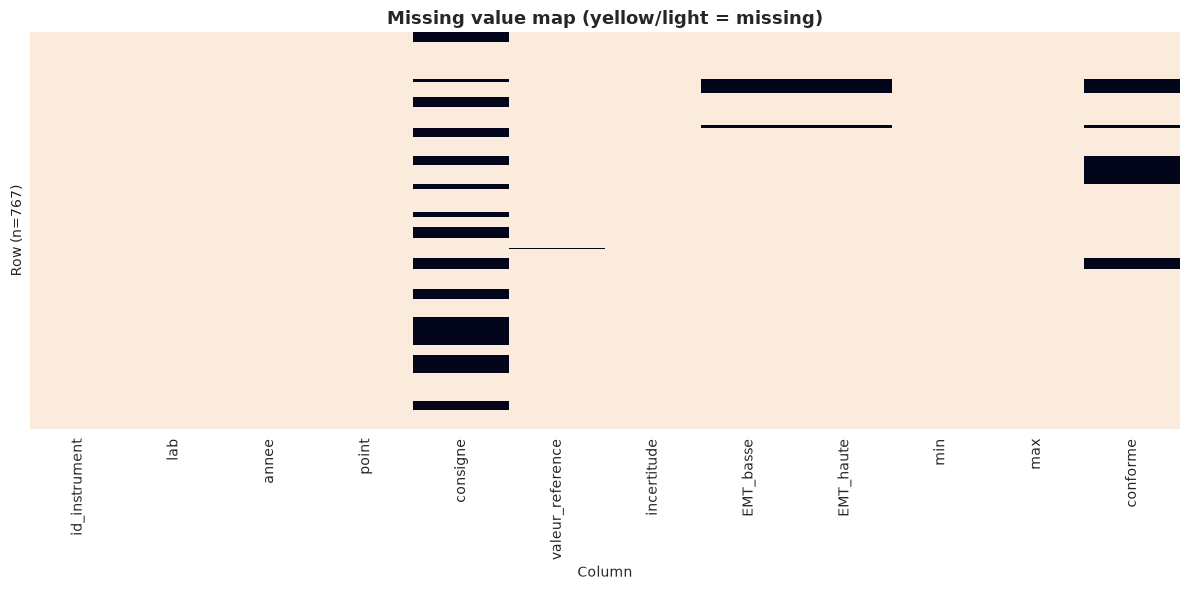

In [32]:

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(df.isna(), cbar=False, cmap="rocket_r", yticklabels=False, ax=ax)
ax.set_title("Missing value map (yellow/light = missing)", fontsize=13, fontweight="bold")
ax.set_xlabel("Column")
ax.set_ylabel(f"Row (n={len(df)})")
ax.grid(False)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "01_missing_value_heatmap.png", dpi=150)
plt.show()


### 7.2 Data type chart

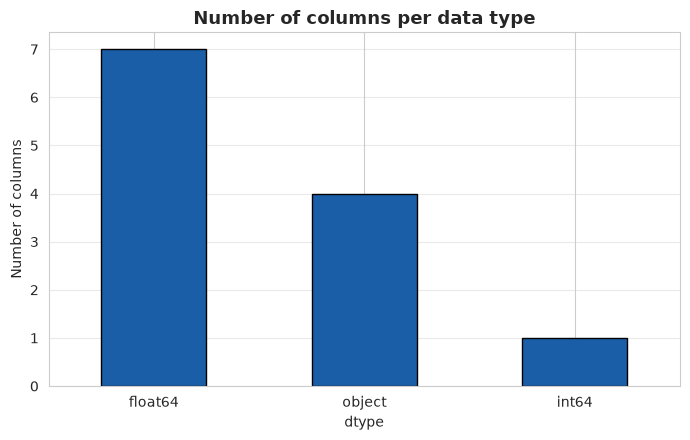

In [33]:

dtype_counts = df.dtypes.astype(str).value_counts()
fig, ax = plt.subplots(figsize=(7, 4.5))
dtype_counts.plot(kind="bar", ax=ax, color="#1B5EA8", edgecolor="black")
ax.set_title("Number of columns per data type", fontsize=13, fontweight="bold")
ax.set_xlabel("dtype")
ax.set_ylabel("Number of columns")
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "02_data_type_chart.png", dpi=150)
plt.show()


### 7.3 Cardinality chart

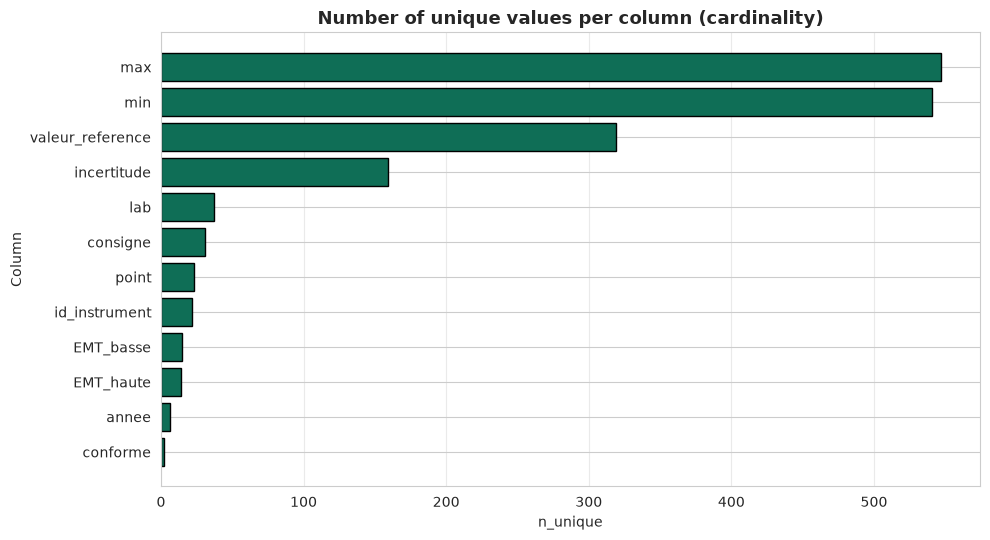

In [34]:

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_data = cardinality_df.sort_values("n_unique", ascending=True)
ax.barh(plot_data["column"], plot_data["n_unique"], color="#0F6E56", edgecolor="black")
ax.set_title("Number of unique values per column (cardinality)", fontsize=13, fontweight="bold")
ax.set_xlabel("n_unique")
ax.set_ylabel("Column")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "03_cardinality_chart.png", dpi=150)
plt.show()


### 7.4 Numerical summary — distributions

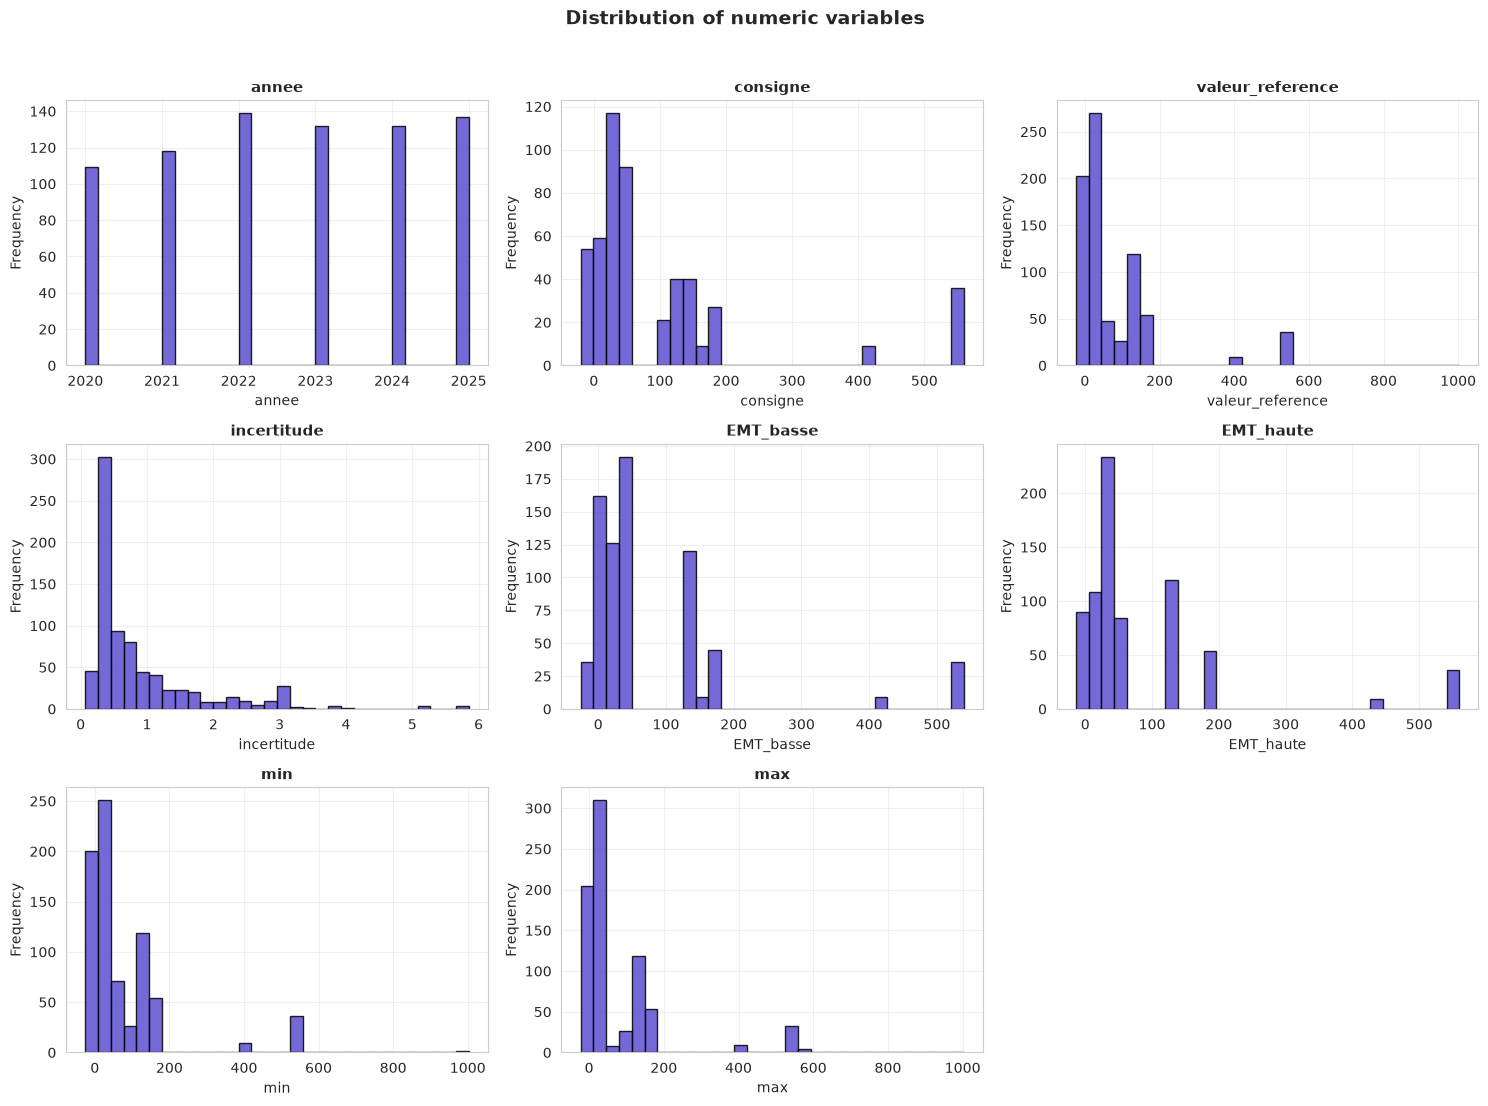

In [35]:

numeric_cols_for_plot = [c for c in numeric_cols if df[c].notna().sum() > 0]
n = len(numeric_cols_for_plot)
ncols_grid = 3
nrows_grid = int(np.ceil(n / ncols_grid))

fig, axes = plt.subplots(nrows_grid, ncols_grid, figsize=(5 * ncols_grid, 3.6 * nrows_grid))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(numeric_cols_for_plot):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=30, color="#5C4FCF", edgecolor="black", alpha=0.85)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Distribution of numeric variables", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "04_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


### 7.5 Categorical summary — top categories

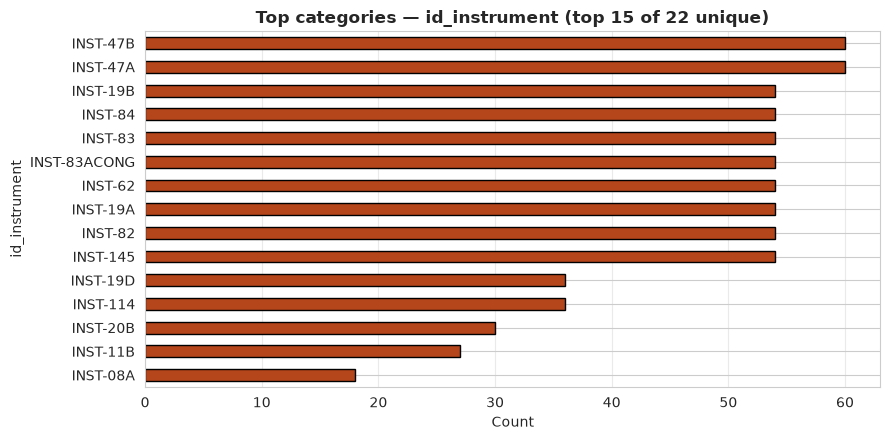

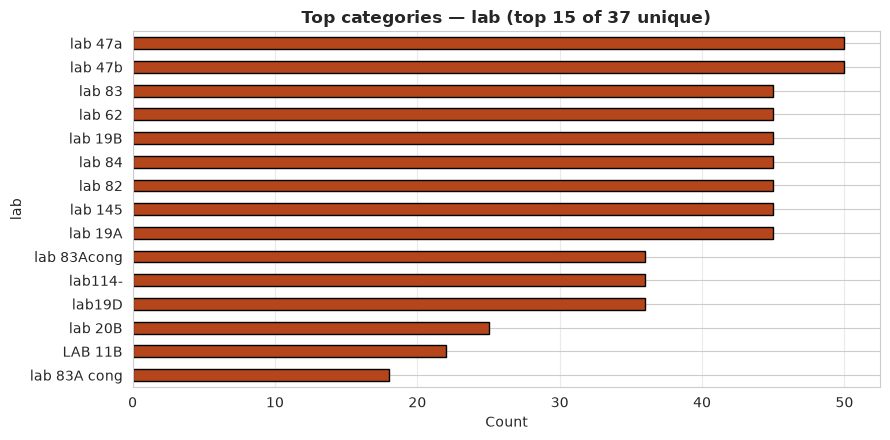

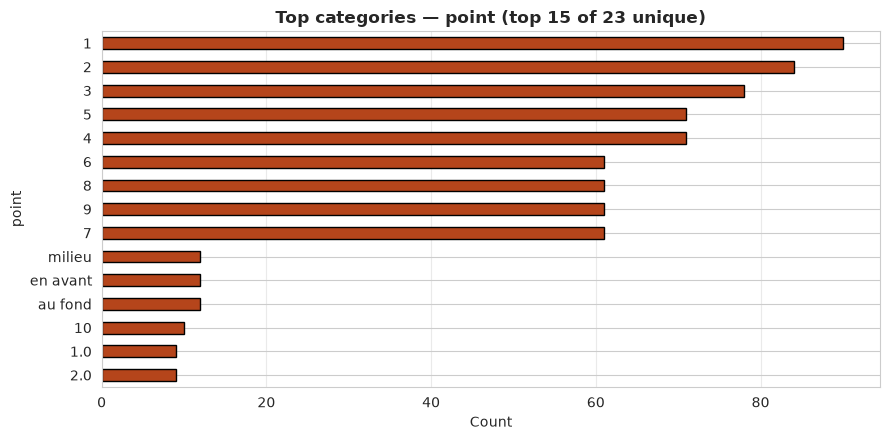

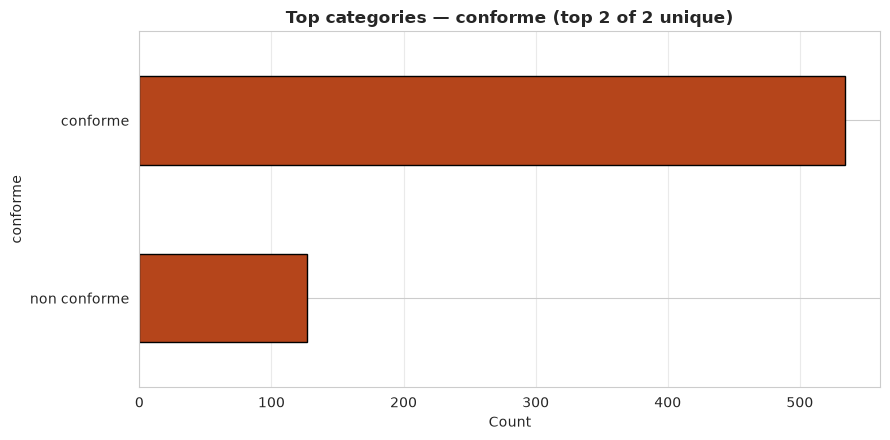

In [36]:

cat_cols_for_plot = [c for c in categorical_cols if c in df.columns and df[c].notna().sum() > 0]

for col in cat_cols_for_plot:
    top_values = df[col].value_counts(dropna=True).head(15)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    top_values.sort_values().plot(kind="barh", ax=ax, color="#B5451B", edgecolor="black")
    ax.set_title(f"Top categories — {col} (top {len(top_values)} of {df[col].nunique()} unique)",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("Count")
    ax.grid(axis="x", alpha=0.4)
    plt.tight_layout()
    safe_name = col.replace('/', '_')
    plt.savefig(REPORTS_FIGURES / f"05_categorical_{safe_name}.png", dpi=150)
    plt.show()


## 8. Initial Conclusions

Everything below is **generated programmatically from the computed results above** —
strengths, weaknesses and next steps are derived from `quality_summary`,
`cardinality_df` and `missing_df`, not asserted by hand.


In [37]:

strengths, weaknesses, preprocessing_tasks, feature_ideas, ml_challenges = [], [], [], [], []

# --- Strengths ---
if n_full_duplicates == 0:
    strengths.append("No fully duplicated rows detected across the whole dataset.")
if (missing_df["missing_pct"] == 0).sum() >= len(df.columns) / 2:
    strengths.append(f"{(missing_df['missing_pct']==0).sum()} / {len(df.columns)} columns have zero missing values.")
if quality_summary[quality_summary["severity"] == "error"].empty:
    strengths.append("No error-level data quality issue detected by the automated checks.")
else:
    strengths.append(f"Only {len(quality_summary[quality_summary['severity']=='error'])} distinct error-level issue type(s) detected — scope is well contained.")

# --- Weaknesses (data-driven) ---
worst_missing = missing_df[missing_df["missing_pct"] > 0].sort_values("missing_pct", ascending=False)
if not worst_missing.empty:
    top_missing = worst_missing.iloc[0]
    weaknesses.append(
        f"Column '{top_missing['column']}' has the highest missing rate "
        f"({top_missing['missing_pct']}%) among {len(worst_missing)} column(s) with missing data."
    )
error_checks = quality_summary[quality_summary["severity"] == "error"]
if not error_checks.empty:
    weaknesses.append(
        f"{len(error_checks)} error-level check(s) triggered, totalling "
        f"{int(error_checks['count'].sum())} flagged row-level occurrences (see section 6.12)."
    )
mixed_type_cols = [row["name"] for _, row in data_dictionary.iterrows()
                    if row["detected_semantic_type"] in ("mixed numeric/text", "numeric-like text (mostly convertible)")]
if mixed_type_cols:
    weaknesses.append(f"Mixed numeric/text representation detected in column(s): {mixed_type_cols}.")

# --- Preprocessing tasks (derived from dictionary + quality report) ---
for _, row in data_dictionary.iterrows():
    if row["missing_pct"] > 0:
        preprocessing_tasks.append(f"Decide an explicit missing-value strategy for '{row['name']}' ({row['missing_pct']}% missing).")
if mixed_type_cols:
    preprocessing_tasks.append(f"Harmonize mixed-type column(s) {mixed_type_cols} into a single consistent representation.")
if not error_checks.empty:
    preprocessing_tasks.append("Route all rows flagged by error-level checks through an explicit exclusion/repair step, with a traceable log (ISO/IEC 17025 auditability).")

# --- Feature engineering ideas (grounded in the ISO/IEC 17025 domain) ---
feature_ideas = [
    "distance_to_EMT = min(min - EMT_basse, EMT_haute - max) — margin to the tolerance limit.",
    "time_since_last_calibration / time_since_last_verification, derived from 'annee' per instrument.",
    "rolling drift trend of 'valeur_reference' (or of the computed error) per id_instrument across years.",
    "uncertainty_ratio = incertitude / (EMT_haute - EMT_basse) — relative measurement confidence.",
    "historical_non_conformity_count per instrument, from the 'conforme' column.",
]

# --- ML challenges (grounded in what was actually measured above) ---
if len(df) < 2000:
    ml_challenges.append(f"Limited dataset size ({len(df)} real rows) — motivates the scientifically-grounded augmentation strategy already used upstream (see src/data/augment_ila.py).")
if not error_checks.empty:
    ml_challenges.append("Label/feature reliability: error-level inconsistencies must be resolved before they propagate into the regression/anomaly-detection targets.")
if mixed_type_cols:
    ml_challenges.append(f"Feature encoding: column(s) {mixed_type_cols} require a harmonization step before numeric modeling.")
ml_challenges.append("Class imbalance risk on 'conforme' should be checked explicitly before using it as any kind of label.")


def print_bullets(title, items):
    print(f"\n{title}")
    print("-" * len(title))
    if not items:
        print("  (none identified by the automated checks)")
    for it in items:
        print(f"  - {it}")


print_bullets("DATASET STRENGTHS", strengths)
print_bullets("DATASET WEAKNESSES", weaknesses)
print_bullets("POTENTIAL PREPROCESSING TASKS", preprocessing_tasks)
print_bullets("POTENTIAL FEATURE ENGINEERING IDEAS", feature_ideas)
print_bullets("POTENTIAL MACHINE LEARNING CHALLENGES", ml_challenges)

logger.info("Notebook 01 completed successfully.")



DATASET STRENGTHS
-----------------
  - No fully duplicated rows detected across the whole dataset.
  - 7 / 12 columns have zero missing values.
  - Only 9 distinct error-level issue type(s) detected — scope is well contained.

DATASET WEAKNESSES
------------------
  - Column 'consigne' has the highest missing rate (34.29%) among 5 column(s) with missing data.
  - 9 error-level check(s) triggered, totalling 42 flagged row-level occurrences (see section 6.12).
  - Mixed numeric/text representation detected in column(s): ['point'].

POTENTIAL PREPROCESSING TASKS
-----------------------------
  - Decide an explicit missing-value strategy for 'consigne' (34.29% missing).
  - Decide an explicit missing-value strategy for 'valeur_reference' (0.13% missing).
  - Decide an explicit missing-value strategy for 'EMT_basse' (4.17% missing).
  - Decide an explicit missing-value strategy for 'EMT_haute' (4.17% missing).
  - Decide an explicit missing-value strategy for 'conforme' (13.82% missing).


---
**End of Notebook 01 — Data Understanding.**

Outputs generated:
- `reports/data_dictionary/Data_Dictionary.xlsx`
- `reports/quality/initial_quality_report.xlsx`
- Figures under `reports/figures/01_data_understanding/`
- Full run log under `logs/01_data_understanding.log`

Per instructions, this notebook stops here awaiting validation before Notebook 02
(Data Cleaning) is generated.
